# MIT Academy of Engineering, Alandi, Pune
## Department of CSE (AI & ML)

**Class:** T.Y.Tech  
**Course:** Generative AI Lab  

# Assignment–02: Comparative Study and Practical Analysis of Generative AI Models

**Group Assignment – 10 Marks (scaled down to 5 Marks)**  
**Course Outcomes:** CO3 and CO4

### Student Information

- **Name of Student:** Sakshi Uttam Walunj
- **PRN / Roll Number:** 202502110007
- **Batch:** A3
- **Date of Submission:**30-10-2026
- **Group Member 2:** Dhanashree Shah
- **Group Member 3:** Shreya Bhosale

### Objective

To understand and analyse image reconstruction and image generation using Autoencoder, Variational Autoencoder, Deep Convolutional GAN and a pretrained Diffusion Model through comparative study and practical experimentation.

### Assignment Structure

- **Part A – CO3:** Image reconstruction using Autoencoder (AE) and Variational Autoencoder (VAE).
- **Part B – CO4:** Image generation using Deep Convolutional GAN (DCGAN) and pretrained Stable Diffusion.
- **Part C:** Comparative analysis, practical output analysis, AI usage documentation and group reflection.

**Dataset:** Fashion-MNIST is used for AE, VAE and DCGAN. Stable Diffusion is demonstrated separately using a text prompt to generate a fashion-product image.

**Notebook naming convention:** `Sakshi_Walunj_GenerativeAILabAssignment.ipynb`

## 1. Problem definition and methodology

The practical compares two different tasks:

1. **Reconstruction:** AE and VAE receive the same test images and attempt to reproduce them. Their quality is measured using mean squared error (MSE) and mean absolute error (MAE).
2. **Generation:** DCGAN learns to generate new Fashion-MNIST-like images from random noise. Stable Diffusion generates a new image from a natural-language prompt using pretrained weights.

The same Fashion-MNIST training and test split is used for AE and VAE. DCGAN uses the Fashion-MNIST training images. Stable Diffusion is a separately pretrained text-to-image model; it is not trained on Fashion-MNIST in this experiment.

## 2. Comparative study of the four models

| Parameter | Autoencoder (AE) | Variational Autoencoder (VAE) | DCGAN | Stable Diffusion |
|---|---|---|---|---|
| Main purpose | Reconstruct input images | Reconstruct and sample from a learned latent distribution | Generate new images | Generate images from text prompts |
| Working principle | Encoder compresses an image; decoder reconstructs it | Encoder predicts latent mean and log-variance; decoder reconstructs a sampled latent vector | Generator creates images; discriminator distinguishes real from generated images | A denoising network iteratively removes noise in latent space, conditioned on text |
| Major components | Encoder, latent representation, decoder | Encoder, mean, log-variance, sampling, decoder | Generator, discriminator, adversarial losses | Text encoder, denoising U-Net, scheduler, VAE |
| Advantages | Simple; useful for reconstruction and feature learning | Structured probabilistic latent space; supports sampling | Learns to create new samples; convolutional architecture suits images | Flexible prompt-conditioned generation and detailed outputs |
| Limitations | May lose fine details; not inherently a text-to-image generator | Reconstructions can be smoother; training balances reconstruction and KL loss | Training can be unstable; may produce artifacts or repeated patterns | High memory/computational cost; prompt adherence and output can vary |
| Applications | Denoising, compression, anomaly detection | Representation learning, interpolation, image generation | Synthetic data, image synthesis | Text-to-image generation, design and creative applications |
| Output in this practical | Reconstruction of an input | Reconstruction of an input / latent sample | New grayscale clothing-like image | New prompt-conditioned fashion image |

## 3. Software, libraries and dataset

- Google Colab with a GPU runtime (T4 recommended for Stable Diffusion).
- TensorFlow/Keras for AE, VAE and DCGAN.
- PyTorch and Hugging Face Diffusers for pretrained Stable Diffusion.
- Fashion-MNIST dataset from `tf.keras.datasets`.
- Matplotlib, NumPy and Pandas for visualization and evaluation.

### Dataset categories

T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag and Ankle boot.

## Student practical record and evidence

The code cells below contain the implementations and experiments. Their executed outputs provide the practical evidence required by Assignment–02:

- Dataset sample images.
- Original and Autoencoder-reconstructed images.
- Original and VAE-reconstructed images.
- AE/VAE test MSE and MAE comparison.
- DCGAN-generated image grid.
- Stable Diffusion prompt and generated image.
- Training-loss plots and saved result files.

The notebook must be executed sequentially in Google Colab before submission so that actual output images, metrics and plots are stored in the notebook. Do not replace experiment outputs with illustrative or manually fabricated screenshots.

## 4. Library imports and reproducibility

In [1]:
import os
import gc
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

# Avoid TensorFlow reserving all GPU memory at startup.
for gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass

TensorFlow: 2.21.0
GPU devices: []


## 5. Output folder and dataset loading

The notebook saves its outputs in Google Drive. If Drive mounting is unavailable, it falls back to the Colab working directory.

In [2]:
OUTPUT_DIR = "/content/GenerativeAI_Assignment02_Results"

try:
    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)
    OUTPUT_DIR = "/content/drive/MyDrive/GenerativeAI_Assignment02_Results"
except Exception as error:
    print("Google Drive is not available; saving results in the Colab session:", error)

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Output directory:", OUTPUT_DIR)

Mounted at /content/drive
Output directory: /content/drive/MyDrive/GenerativeAI_Assignment02_Results


In [3]:
# Load Fashion-MNIST.
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

# Normalize pixels to [0, 1] and add the grayscale channel dimension.
x_train_images = (x_train.astype("float32") / 255.0)[..., np.newaxis]
x_test_images = (x_test.astype("float32") / 255.0)[..., np.newaxis]

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

print("Training images:", x_train_images.shape)
print("Test images:", x_test_images.shape)
print("Pixel range:", float(x_train_images.min()), "to", float(x_train_images.max()))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28, 1)
Test images: (10000, 28, 28, 1)
Pixel range: 0.0 to 1.0


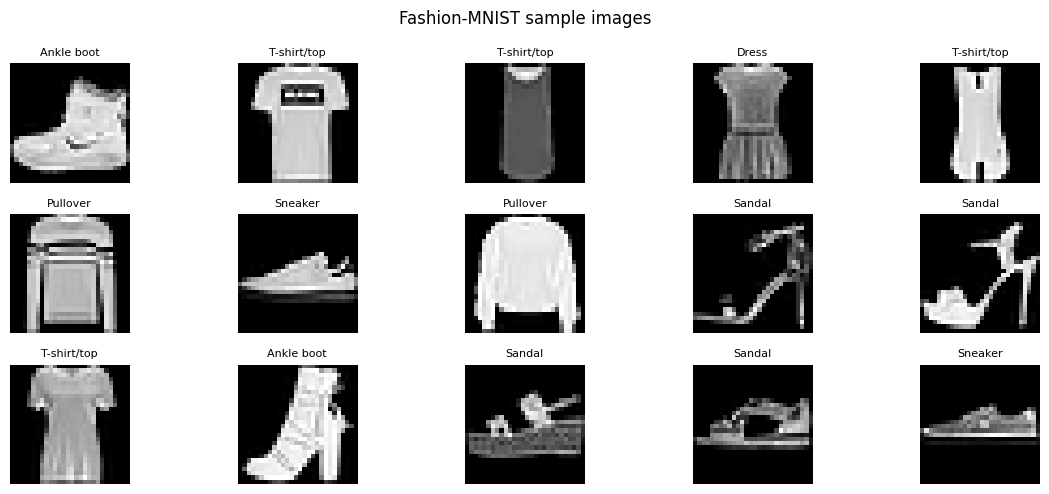

In [4]:
# Display representative dataset images.
plt.figure(figsize=(12, 5))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train_images[i].squeeze(), cmap="gray")
    plt.title(class_names[int(y_train[i])], fontsize=8)
    plt.axis("off")
plt.suptitle("Fashion-MNIST sample images")
plt.tight_layout()
plt.show()

# Part A – CO3: Image reconstruction

## 6. Experiment 1 – Convolutional Autoencoder

### Architecture and working

The encoder applies convolution and downsampling to obtain a compact latent representation. The decoder upsamples the representation to reconstruct a 28 × 28 grayscale image. The model is trained to minimize pixel-wise reconstruction error.

In [5]:
latent_dim = 128

ae_encoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, 3, strides=2, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(64, 3, strides=2, padding="same", activation="relu"),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(latent_dim, activation="relu")
], name="AE_Encoder")

ae_decoder = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(latent_dim,)),
    tf.keras.layers.Dense(7 * 7 * 64, activation="relu"),
    tf.keras.layers.Reshape((7, 7, 64)),
    tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu"),
    tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(1, 3, padding="same", activation="sigmoid")
], name="AE_Decoder")

ae_input = tf.keras.Input(shape=(28, 28, 1))
ae_output = ae_decoder(ae_encoder(ae_input))
autoencoder = tf.keras.Model(ae_input, ae_output, name="Convolutional_Autoencoder")
autoencoder.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="mse")
autoencoder.summary()

Model: "Convolutional_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AE_Encoder (Sequential)         │ (None, 128)            │       420,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ AE_Decoder (Sequential)         │ (None, 28, 28, 1)      │       460,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 880,577 (3.36 MB)

 Trainable params: 880,577 (3.36 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Train the Autoencoder. Full Fashion-MNIST training split is used.
AE_EPOCHS = 10
ae_history = autoencoder.fit(
    x_train_images, x_train_images,
    epochs=AE_EPOCHS,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_images, x_test_images),
    verbose=1
)

autoencoder.save_weights(os.path.join(OUTPUT_DIR, "autoencoder.weights.h5"))
print("Autoencoder weights saved.")

Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 84s 349ms/step - loss: 0.0400 - val_loss: 0.0166
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 78s 331ms/step - loss: 0.0140 - val_loss: 0.0122
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 83s 336ms/step - loss: 0.0110 - val_loss: 0.0100
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 77s 326ms/step - loss: 0.0094 - val_loss: 0.0091
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 77s 327ms/step - loss: 0.0084 - val_loss: 0.0084
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 77s 327ms/step - loss: 0.0077 - val_loss: 0.0075
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 81s 322ms/step - loss: 0.0072 - val_loss: 0.0070
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 83s 329ms/step - loss: 0.0068 - val_loss: 0.0067
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 82s 331ms/step - loss: 0.0064 - val_loss: 0.0063
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 85s 346ms/step - loss: 0.0061 - val_loss: 0.0064
Autoencoder weights saved.


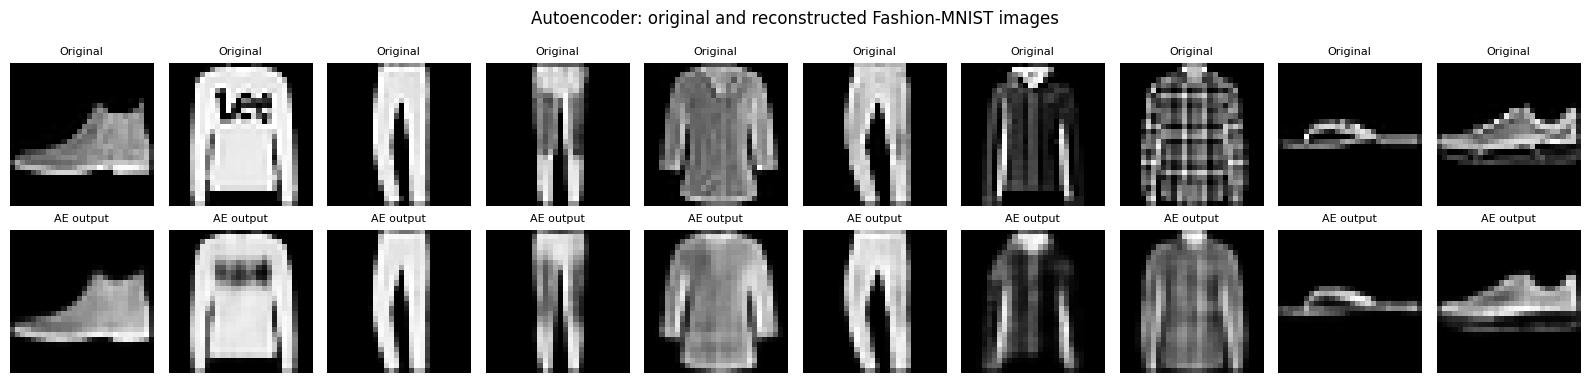

Autoencoder test MSE: 0.006448
Autoencoder test MAE: 0.039754


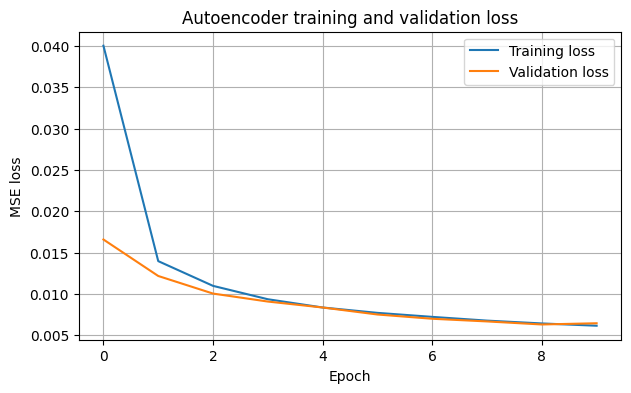

In [7]:
# Reconstruct the same test images and visualize original vs reconstructed.
NUM_SHOW = 10
ae_reconstructions = autoencoder.predict(x_test_images[:NUM_SHOW], verbose=0)

fig, axes = plt.subplots(2, NUM_SHOW, figsize=(16, 4))
for i in range(NUM_SHOW):
    axes[0, i].imshow(x_test_images[i].squeeze(), cmap="gray")
    axes[0, i].set_title("Original", fontsize=8)
    axes[0, i].axis("off")
    axes[1, i].imshow(ae_reconstructions[i].squeeze(), cmap="gray")
    axes[1, i].set_title("AE output", fontsize=8)
    axes[1, i].axis("off")
axes[0, 0].set_ylabel("Input")
axes[1, 0].set_ylabel("Reconstruction")
plt.suptitle("Autoencoder: original and reconstructed Fashion-MNIST images")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "autoencoder_reconstruction.png"), dpi=200, bbox_inches="tight")
plt.show()

ae_test_reconstructions = autoencoder.predict(x_test_images, batch_size=256, verbose=0)
ae_mse = float(np.mean(np.square(x_test_images - ae_test_reconstructions)))
ae_mae = float(np.mean(np.abs(x_test_images - ae_test_reconstructions)))
print(f"Autoencoder test MSE: {ae_mse:.6f}")
print(f"Autoencoder test MAE: {ae_mae:.6f}")

plt.figure(figsize=(7, 4))
plt.plot(ae_history.history["loss"], label="Training loss")
plt.plot(ae_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("Autoencoder training and validation loss")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(OUTPUT_DIR, "autoencoder_loss.png"), dpi=200, bbox_inches="tight")
plt.show()

## 7. Experiment 2 – Variational Autoencoder (VAE)

### Architecture and working

The VAE encoder predicts a latent mean and log-variance. A sampling layer uses the reparameterization trick to obtain a latent vector. The decoder reconstructs the input. The objective combines reconstruction loss and KL-divergence regularization.

In [8]:
vae_latent_dim = 64
BETA = 0.25

class Sampling(tf.keras.layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs
        epsilon = tf.random.normal(shape=tf.shape(z_mean))
        return z_mean + tf.exp(0.5 * z_log_var) * epsilon

vae_input = tf.keras.Input(shape=(28, 28, 1))
h = tf.keras.layers.Conv2D(32, 3, strides=2, padding="same", activation="relu")(vae_input)
h = tf.keras.layers.Conv2D(64, 3, strides=2, padding="same", activation="relu")(h)
h = tf.keras.layers.Flatten()(h)
h = tf.keras.layers.Dense(256, activation="relu")(h)
z_mean = tf.keras.layers.Dense(vae_latent_dim, name="z_mean")(h)
z_log_var = tf.keras.layers.Dense(vae_latent_dim, name="z_log_var")(h)
z_sample = Sampling()([z_mean, z_log_var])

vae_encoder = tf.keras.Model(vae_input, [z_mean, z_log_var, z_sample], name="VAE_Encoder")

latent_input = tf.keras.Input(shape=(vae_latent_dim,))
h = tf.keras.layers.Dense(7 * 7 * 64, activation="relu")(latent_input)
h = tf.keras.layers.Reshape((7, 7, 64))(h)
h = tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(h)
h = tf.keras.layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu")(h)
decoder_output = tf.keras.layers.Conv2D(1, 3, padding="same", activation="sigmoid")(h)
vae_decoder = tf.keras.Model(latent_input, decoder_output, name="VAE_Decoder")

class VariationalAutoencoder(tf.keras.Model):
    def __init__(self, encoder, decoder, beta=0.25, **kwargs):
        super().__init__(**kwargs)
        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta
        self.total_loss_tracker = tf.keras.metrics.Mean(name="loss")
        self.reconstruction_tracker = tf.keras.metrics.Mean(name="reconstruction_loss")
        self.kl_tracker = tf.keras.metrics.Mean(name="kl_loss")

    @property
    def metrics(self):
        return [self.total_loss_tracker, self.reconstruction_tracker, self.kl_tracker]

    def calculate_losses(self, images, training=False):
        mean, log_var, sampled_z = self.encoder(images, training=training)
        reconstruction = self.decoder(sampled_z, training=training)
        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(
                tf.keras.losses.binary_crossentropy(images, reconstruction),
                axis=(1, 2)
            )
        )
        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(1 + log_var - tf.square(mean) - tf.exp(log_var), axis=1)
        )
        total_loss = reconstruction_loss + self.beta * kl_loss
        return total_loss, reconstruction_loss, kl_loss

    def train_step(self, data):
        images = data[0] if isinstance(data, (tuple, list)) else data
        with tf.GradientTape() as tape:
            total_loss, reconstruction_loss, kl_loss = self.calculate_losses(images, training=True)
        gradients = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(gradients, self.trainable_variables))
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_tracker.update_state(reconstruction_loss)
        self.kl_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

    def test_step(self, data):
        images = data[0] if isinstance(data, (tuple, list)) else data
        total_loss, reconstruction_loss, kl_loss = self.calculate_losses(images, training=False)
        self.total_loss_tracker.update_state(total_loss)
        self.reconstruction_tracker.update_state(reconstruction_loss)
        self.kl_tracker.update_state(kl_loss)
        return {metric.name: metric.result() for metric in self.metrics}

    def call(self, inputs, training=False):
        mean, log_var, sampled_z = self.encoder(inputs, training=training)
        return self.decoder(sampled_z, training=training)

vae = VariationalAutoencoder(vae_encoder, vae_decoder, beta=BETA, name="Variational_Autoencoder")
vae.compile(optimizer=tf.keras.optimizers.Adam(1e-3))
_ = vae(x_train_images[:1])
vae.summary()

Model: "Variational_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ VAE_Encoder (Functional)        │ ((None, 64), (None,    │       854,784 │
│                                 │ 64), (None, 64))       │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ VAE_Decoder (Functional)        │ (None, 28, 28, 1)      │       259,521 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,114,305 (4.25 MB)

 Trainable params: 1,114,305 (4.25 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
# Train VAE with explicit validation handling.
VAE_EPOCHS = 12
vae_history = vae.fit(
    x_train_images,
    epochs=VAE_EPOCHS,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test_images, x_test_images),
    verbose=1
)

vae_encoder.save_weights(os.path.join(OUTPUT_DIR, "vae_encoder.weights.h5"))
vae_decoder.save_weights(os.path.join(OUTPUT_DIR, "vae_decoder.weights.h5"))
print("VAE encoder and decoder weights saved.")

Epoch 1/12
235/235 ━━━━━━━━━━━━━━━━━━━━ 89s 373ms/step - kl_loss: 34.1624 - loss: 304.2467 - reconstruction_loss: 295.7061 - val_kl_loss: 41.5499 - val_loss: 252.9395 - val_reconstruction_loss: 242.5520
Epoch 2/12
235/235 ━━━━━━━━━━━━━━━━━━━━ 137s 351ms/step - kl_loss: 42.0781 - loss: 244.9083 - reconstruction_loss: 234.3889 - val_kl_loss: 41.6421 - val_loss: 241.2620 - val_reconstruction_loss: 230.8514
Epoch 3/12
235/235 ━━━━━━━━━━━━━━━━━━━━ 145s 366ms/step - kl_loss: 41.1891 - loss: 236.5653 - reconstruction_loss: 226.2680 - val_kl_loss: 40.1645 - val_loss: 235.5280 - val_reconstruction_loss: 225.4868
Epoch 4/12
235/235 ━━━━━━━━━━━━━━━━━━━━ 142s 366ms/step - kl_loss: 39.8589 - loss: 232.0024 - reconstruction_loss: 222.0376 - val_kl_loss: 39.4518 - val_loss: 231.7042 - val_reconstruction_loss: 221.8413
Epoch 5/12
235/235 ━━━━━━━━━━━━━━━━━━━━ 86s 366ms/step - kl_loss: 38.9328 - loss: 229.1778 - reconstruction_loss: 219.4445 - val_kl_loss: 39.2456 - val_loss: 229.3433 - val_reconstructi

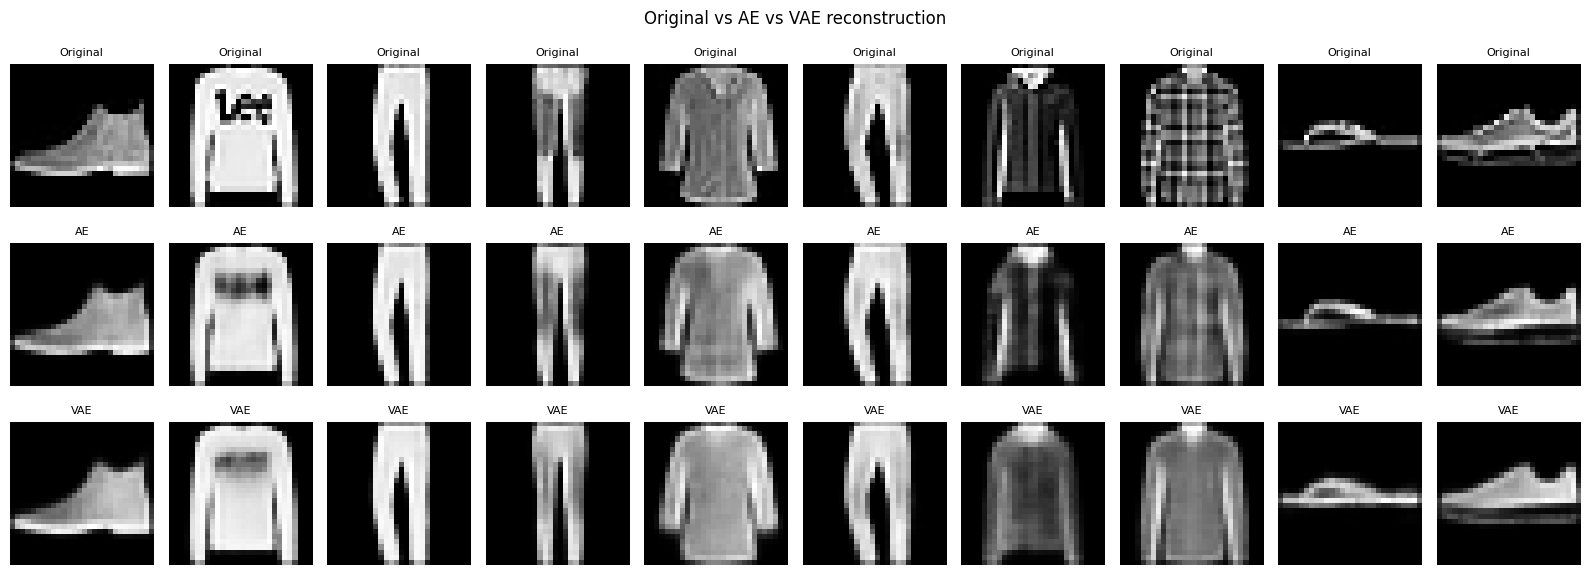

VAE test MSE: 0.009283
VAE test MAE: 0.047689


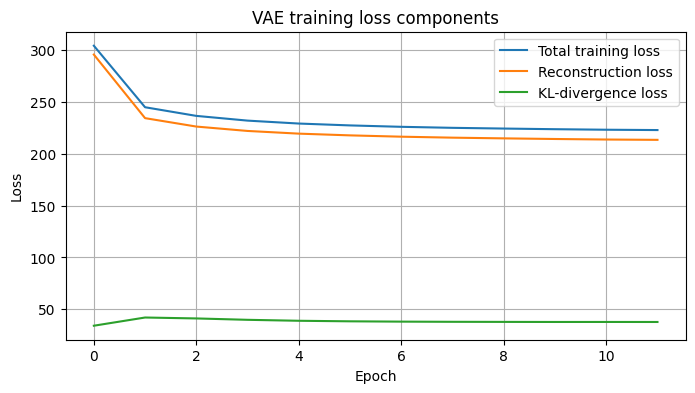

In [10]:
# Use the posterior mean for deterministic reconstruction.
vae_mean_test, vae_log_var_test, _ = vae_encoder.predict(x_test_images[:NUM_SHOW], verbose=0)
vae_reconstructions = vae_decoder.predict(vae_mean_test, verbose=0)

fig, axes = plt.subplots(3, NUM_SHOW, figsize=(16, 6))
for i in range(NUM_SHOW):
    axes[0, i].imshow(x_test_images[i].squeeze(), cmap="gray")
    axes[0, i].set_title("Original", fontsize=8)
    axes[0, i].axis("off")
    axes[1, i].imshow(ae_reconstructions[i].squeeze(), cmap="gray")
    axes[1, i].set_title("AE", fontsize=8)
    axes[1, i].axis("off")
    axes[2, i].imshow(vae_reconstructions[i].squeeze(), cmap="gray")
    axes[2, i].set_title("VAE", fontsize=8)
    axes[2, i].axis("off")
axes[0, 0].set_ylabel("Input")
axes[1, 0].set_ylabel("AE output")
axes[2, 0].set_ylabel("VAE output")
plt.suptitle("Original vs AE vs VAE reconstruction")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "ae_vae_reconstruction_comparison.png"), dpi=200, bbox_inches="tight")
plt.show()

vae_mean_all, _, _ = vae_encoder.predict(x_test_images, batch_size=256, verbose=0)
vae_test_reconstructions = vae_decoder.predict(vae_mean_all, batch_size=256, verbose=0)
vae_mse = float(np.mean(np.square(x_test_images - vae_test_reconstructions)))
vae_mae = float(np.mean(np.abs(x_test_images - vae_test_reconstructions)))
print(f"VAE test MSE: {vae_mse:.6f}")
print(f"VAE test MAE: {vae_mae:.6f}")

plt.figure(figsize=(8, 4))
plt.plot(vae_history.history["loss"], label="Total training loss")
plt.plot(vae_history.history["reconstruction_loss"], label="Reconstruction loss")
plt.plot(vae_history.history["kl_loss"], label="KL-divergence loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE training loss components")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(OUTPUT_DIR, "vae_loss.png"), dpi=200, bbox_inches="tight")
plt.show()

### AE and VAE output analysis

Both models reconstruct the same Fashion-MNIST test inputs. The AE learns a deterministic compressed representation, whereas the VAE learns a distribution in latent space. Compare the displayed outputs for preservation of clothing silhouette, edges and small details. The MSE and MAE values are calculated on the complete test set; lower values indicate smaller pixel-wise reconstruction error. Visual quality should also be considered because a single pixel metric does not fully describe perceptual quality.

# Part B – CO4: Image generation

## 8. Experiment 3 – Deep Convolutional GAN (DCGAN)

### Architecture and working

DCGAN has two networks trained adversarially. The generator maps random noise to a 28 × 28 grayscale image. The discriminator predicts whether an image is real or generated. The generator learns to produce images that can fool the discriminator.

In [11]:
# Prepare Fashion-MNIST images for DCGAN in the [-1, 1] range.
x_train_gan = (x_train_images * 2.0) - 1.0
GAN_BATCH_SIZE = 128
gan_dataset = (
    tf.data.Dataset.from_tensor_slices(x_train_gan)
    .shuffle(60000, seed=SEED)
    .batch(GAN_BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

noise_dim = 100

generator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(noise_dim,)),
    tf.keras.layers.Dense(7 * 7 * 128, use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Reshape((7, 7, 128)),
    tf.keras.layers.Conv2DTranspose(64, 4, strides=2, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Conv2DTranspose(32, 4, strides=2, padding="same", use_bias=False),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Conv2D(1, 3, padding="same", activation="tanh")
], name="DCGAN_Generator")

discriminator = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(64, 4, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Conv2D(128, 4, strides=2, padding="same"),
    tf.keras.layers.LeakyReLU(negative_slope=0.2),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(1)
], name="DCGAN_Discriminator")

generator.summary()
discriminator.summary()

Model: "DCGAN_Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 14, 14, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 32)     │        32,768 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 816,801 (3.12 MB)

 Trainable params: 804,065 (3.07 MB)

 Non-trainable params: 12,736 (49.75 KB)

Model: "DCGAN_Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_7 (Conv2D)               │ (None, 14, 14, 64)     │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 7, 7, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 138,561 (541.25 KB)

 Trainable params: 138,561 (541.25 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# Configure adversarial losses and optimizers.
cross_entropy = tf.keras.losses.BinaryCrossentropy(from_logits=True)
generator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)
discriminator_optimizer = tf.keras.optimizers.Adam(learning_rate=0.0002, beta_1=0.5)

def generator_loss(fake_output):
    return cross_entropy(tf.ones_like(fake_output), fake_output)

def discriminator_loss(real_output, fake_output):
    real_loss = cross_entropy(tf.ones_like(real_output), real_output)
    fake_loss = cross_entropy(tf.zeros_like(fake_output), fake_output)
    return real_loss + fake_loss

@tf.function
def dcgan_train_step(real_images):
    noise = tf.random.normal([tf.shape(real_images)[0], noise_dim])
    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:
        generated = generator(noise, training=True)
        real_output = discriminator(real_images, training=True)
        fake_output = discriminator(generated, training=True)
        gen_loss = generator_loss(fake_output)
        disc_loss = discriminator_loss(real_output, fake_output)
    gen_gradients = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_gradients = disc_tape.gradient(disc_loss, discriminator.trainable_variables)
    generator_optimizer.apply_gradients(zip(gen_gradients, generator.trainable_variables))
    discriminator_optimizer.apply_gradients(zip(disc_gradients, discriminator.trainable_variables))
    return gen_loss, disc_loss

In [13]:
# Train DCGAN. A fixed noise batch is retained for visual comparison across epochs.
DCGAN_EPOCHS = 15
fixed_noise = tf.random.normal([16, noise_dim], seed=SEED)
dcgan_generator_losses = []
dcgan_discriminator_losses = []

for epoch in range(DCGAN_EPOCHS):
    gen_metric = tf.keras.metrics.Mean()
    disc_metric = tf.keras.metrics.Mean()
    for real_batch in gan_dataset:
        gen_loss_value, disc_loss_value = dcgan_train_step(real_batch)
        gen_metric.update_state(gen_loss_value)
        disc_metric.update_state(disc_loss_value)
    dcgan_generator_losses.append(float(gen_metric.result()))
    dcgan_discriminator_losses.append(float(disc_metric.result()))
    print(
        f"Epoch {epoch + 1:02d}/{DCGAN_EPOCHS} | "
        f"Generator loss: {gen_metric.result():.4f} | "
        f"Discriminator loss: {disc_metric.result():.4f}"
    )

generator.save_weights(os.path.join(OUTPUT_DIR, "dcgan_generator.weights.h5"))
discriminator.save_weights(os.path.join(OUTPUT_DIR, "dcgan_discriminator.weights.h5"))
print("DCGAN weights saved.")

Epoch 01/15 | Generator loss: 0.7090 | Discriminator loss: 1.3407
Epoch 02/15 | Generator loss: 0.7980 | Discriminator loss: 1.2440
Epoch 03/15 | Generator loss: 0.8943 | Discriminator loss: 1.1886
Epoch 04/15 | Generator loss: 0.8225 | Discriminator loss: 1.2676
Epoch 05/15 | Generator loss: 0.7990 | Discriminator loss: 1.2904
Epoch 06/15 | Generator loss: 0.7849 | Discriminator loss: 1.3073
Epoch 07/15 | Generator loss: 0.7777 | Discriminator loss: 1.3116
Epoch 08/15 | Generator loss: 0.7756 | Discriminator loss: 1.3142
Epoch 09/15 | Generator loss: 0.7769 | Discriminator loss: 1.3173
Epoch 10/15 | Generator loss: 0.7783 | Discriminator loss: 1.3149
Epoch 11/15 | Generator loss: 0.7823 | Discriminator loss: 1.3107
Epoch 12/15 | Generator loss: 0.7834 | Discriminator loss: 1.3105
Epoch 13/15 | Generator loss: 0.7823 | Discriminator loss: 1.3134
Epoch 14/15 | Generator loss: 0.7827 | Discriminator loss: 1.3158
Epoch 15/15 | Generator loss: 0.7858 | Discriminator loss: 1.3156
DCGAN weig

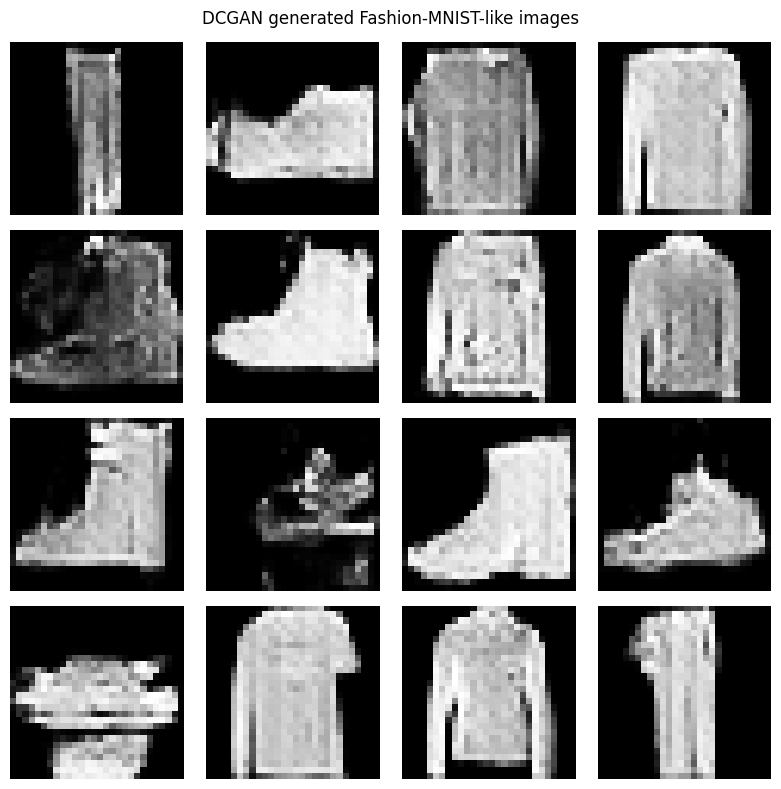

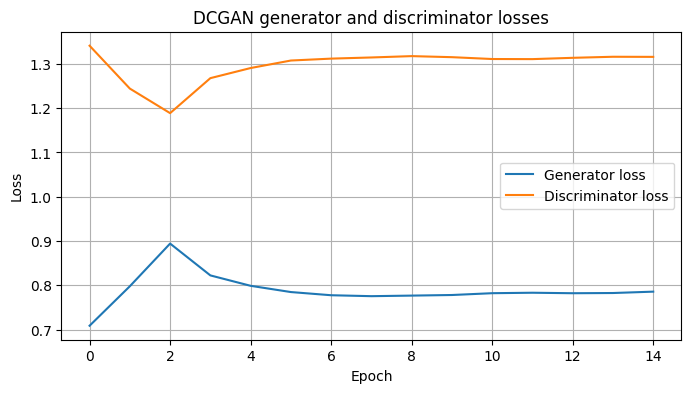

DCGAN generated images saved.


In [14]:
# Generate 16 new images from random noise.
generated_images = generator(fixed_noise, training=False).numpy()
generated_images_display = np.clip((generated_images + 1.0) / 2.0, 0.0, 1.0)

plt.figure(figsize=(8, 8))
for i in range(16):
    plt.subplot(4, 4, i + 1)
    plt.imshow(generated_images_display[i].squeeze(), cmap="gray")
    plt.axis("off")
plt.suptitle("DCGAN generated Fashion-MNIST-like images")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "dcgan_generated_grid.png"), dpi=200, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(dcgan_generator_losses, label="Generator loss")
plt.plot(dcgan_discriminator_losses, label="Discriminator loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DCGAN generator and discriminator losses")
plt.legend()
plt.grid(True)
plt.savefig(os.path.join(OUTPUT_DIR, "dcgan_losses.png"), dpi=200, bbox_inches="tight")
plt.show()

np.save(os.path.join(OUTPUT_DIR, "dcgan_generated_images.npy"), generated_images_display)
print("DCGAN generated images saved.")

### DCGAN output analysis

The 16 images are newly generated samples; they are not reconstructions of the training images. Compare their clothing-like shapes, sharpness and diversity. DCGAN outputs may contain blur, incomplete shapes or artifacts, particularly with a modest training duration. The generator and discriminator loss curves provide a view of adversarial training behaviour but do not alone prove image quality.

## 9. Experiment 4 – Pretrained Diffusion Model: Stable Diffusion

### Working principle

Stable Diffusion is a pretrained latent diffusion model. A text encoder represents the prompt, and a denoising U-Net progressively removes noise from a latent representation. The model's VAE decoder converts the final latent representation into an image.

### Practical generation

A pretrained Stable Diffusion v1.5 pipeline is used to generate a fashion-product image. This model is not trained on Fashion-MNIST in this experiment. The generated output is evaluated against the text prompt.

**Dependency note:** This section requires the Diffusers libraries and a download of pretrained Stable Diffusion weights on the first execution. It is the only section that requires a substantial model download. Use a Colab GPU runtime. The code uses CPU offloading and attention slicing to reduce GPU memory use. If the session crashes during model loading or inference, reconnect and rerun only this section after the AE/VAE/DCGAN results have been saved to Drive.

In [15]:
# Install only the inference libraries required by this section.
%pip -q install diffusers transformers accelerate safetensors

In [16]:
# Release TensorFlow model memory before loading the PyTorch diffusion pipeline.
import gc
import torch
from diffusers import StableDiffusionPipeline
from IPython.display import display

# Preserve all previously calculated scalar metrics and saved output files.
for variable_name in [
    "autoencoder", "ae_encoder", "ae_decoder",
    "vae", "vae_encoder", "vae_decoder",
    "generator", "discriminator", "gan_dataset",
    "ae_history", "vae_history"
]:
    globals().pop(variable_name, None)

gc.collect()
tf.keras.backend.clear_session()
gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("TensorFlow models released from memory.")
print("CUDA available to PyTorch:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

TensorFlow models released from memory.
CUDA available to PyTorch: False


In [17]:
# Load pretrained Stable Diffusion v1.5 using memory-efficient CPU offloading.
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
diffusion_dtype = torch.float16 if torch.cuda.is_available() else torch.float32

stable_diffusion = StableDiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=diffusion_dtype,
    use_safetensors=True
)

stable_diffusion.enable_attention_slicing()

if torch.cuda.is_available():
    # Moves model components between CPU and GPU during inference.
    stable_diffusion.enable_model_cpu_offload()
else:
    stable_diffusion = stable_diffusion.to("cpu")

print("Stable Diffusion pipeline loaded.")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Stable Diffusion pipeline loaded.


  0%|          | 0/20 [00:00<?, ?it/s]

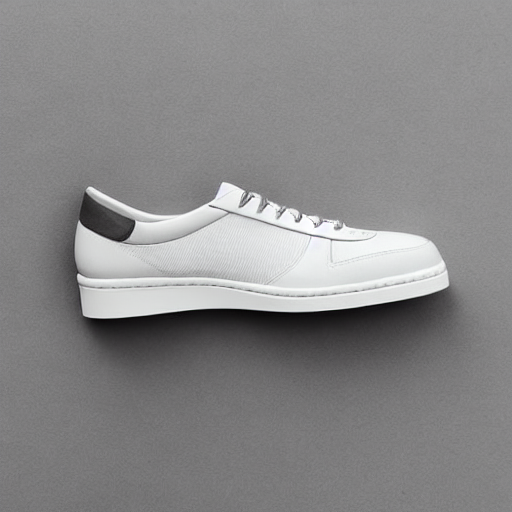

Prompt: A high-quality studio product photograph of a single classic white sneaker, side view, isolated on a clean light grey background, soft studio lighting, sharp details, realistic material texture
Stable Diffusion image saved.


In [18]:
# Generate one fashion-product image from a text prompt.
prompt = (
    "A high-quality studio product photograph of a single classic white sneaker, "
    "side view, isolated on a clean light grey background, soft studio lighting, "
    "sharp details, realistic material texture"
)
negative_prompt = (
    "blurry, distorted, low resolution, multiple shoes, cropped object, "
    "watermark, text, logo"
)

diffusion_generator = torch.Generator(device="cpu").manual_seed(SEED)

with torch.inference_mode():
    diffusion_result = stable_diffusion(
        prompt=prompt,
        negative_prompt=negative_prompt,
        num_inference_steps=20,
        guidance_scale=7.0,
        height=512,
        width=512,
        generator=diffusion_generator
    )

diffusion_image = diffusion_result.images[0]
display(diffusion_image)
print("Prompt:", prompt)

diffusion_image.save(os.path.join(OUTPUT_DIR, "stable_diffusion_sneaker.png"))
print("Stable Diffusion image saved.")

### Stable Diffusion output analysis

The generated image is a new prompt-conditioned image rather than a reconstruction of a Fashion-MNIST sample. Evaluate whether it follows the sneaker prompt, whether the object is visually coherent, and how its resolution and detail compare with the 28 × 28 grayscale DCGAN samples. The comparison is qualitative because the two generation methods use different input conditions and output resolutions.

# Part C – Comparative analysis

## 10. Quantitative comparison of reconstruction models

MSE and MAE are calculated from the complete Fashion-MNIST test split. They apply to AE and VAE reconstruction only; they are not directly comparable to DCGAN or Stable Diffusion, which generate new images rather than reconstruct a paired input.

In [19]:
reconstruction_results = pd.DataFrame({
    "Model": ["Convolutional Autoencoder", "Variational Autoencoder"],
    "Test MSE": [ae_mse, vae_mse],
    "Test MAE": [ae_mae, vae_mae]
})
display(reconstruction_results)

reconstruction_results.to_csv(
    os.path.join(OUTPUT_DIR, "reconstruction_comparison.csv"),
    index=False
)
print("Reconstruction metrics saved.")

,Model,Test MSE,Test MAE
0,Convolutional Autoencoder,0.006448,0.039754
1,Variational Autoencoder,0.009283,0.047689


Reconstruction metrics saved.


## 11. Practical output comparison

### Image reconstruction (CO3)
AE and VAE receive the same Fashion-MNIST test images. Compare the preservation of clothing shape, boundaries and small details in the original and reconstructed rows. Use the test MSE and MAE table as numerical evidence. A lower error indicates closer pixel-wise reconstruction, although it does not always mean better perceived image quality.

### Image generation (CO4)
DCGAN generates new 28 × 28 grayscale clothing-like samples from random noise. Stable Diffusion generates a 512 × 512 product image from a text prompt. Compare realism, detail, resolution, diversity, prompt control and computational requirements. Since their input conditions and image resolutions differ, this is a qualitative comparison rather than a direct pixel-wise metric comparison.

## 12. Group reflection and AI usage documentation

### AI tools and software used
- ChatGPT: assistance with code structure, explanations, debugging and comparative analysis.
- Google Colab: practical execution environment.
- TensorFlow/Keras: AE, VAE and DCGAN implementation.
- PyTorch and Hugging Face Diffusers: pretrained Stable Diffusion inference.

### Important prompts used
1. Explain and compare the working principles and architectures of Autoencoder, VAE, DCGAN and Diffusion Models.
2. Develop an image reconstruction experiment using Autoencoder and VAE on Fashion-MNIST.
3. Implement a DCGAN to generate Fashion-MNIST-like images.
4. Demonstrate text-to-image generation using pretrained Stable Diffusion.
5. Compare reconstruction and generation outputs using appropriate visual and quantitative observations.

### Verification process
- Checked Fashion-MNIST training/test dimensions, image shape and pixel range.
- Used the same test images for AE and VAE reconstruction.
- Calculated MSE and MAE over the complete test split.
- Inspected original/reconstructed images and training-loss curves.
- Inspected DCGAN generated samples and generator/discriminator losses.
- Compared Stable Diffusion output with its text prompt.
- Cross-checked implementation concepts with official TensorFlow/Keras and Hugging Face documentation.

### Key learning outcomes
- Distinguished image reconstruction from image generation.
- Understood deterministic and probabilistic latent representations.
- Studied the role of KL divergence in VAE training.
- Understood adversarial learning through a DCGAN generator and discriminator.
- Explored prompt-conditioned image generation using a pretrained diffusion model.
- Compared model outputs, strengths, limitations and computational requirements.

### Group member contributions
Complete the names and actual contributions of all three members before submission.

- **Member 1 – Name:** ______________________________________________  
  **Contribution:** _________________________________________________

- **Member 2 – Name:** ______________________________________________  
  **Contribution:** _________________________________________________

- **Member 3 – Name:** ______________________________________________  
  **Contribution:** _________________________________________________

## 13. Conclusion

This practical study compares two image reconstruction models and two image generation models. The Autoencoder and VAE reconstruct Fashion-MNIST inputs using learned latent representations, while DCGAN generates new grayscale clothing-like images through adversarial learning. Stable Diffusion generates a prompt-conditioned fashion image using pretrained diffusion weights.

The experiments demonstrate that model architecture, training strategy, latent-space representation, dataset characteristics and computational resources influence the resulting image quality. AE and VAE are evaluated using the same test images and reconstruction metrics, while DCGAN and Stable Diffusion are analysed through their generated outputs. The numerical and visual evidence should be interpreted together.

## References

1. Xiao, H., Rasul, K. and Vollgraf, R. (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms*.  
2. Keras, Fashion-MNIST dataset documentation: https://keras.io/api/datasets/fashion_mnist/  
3. TensorFlow, Keras API documentation: https://www.tensorflow.org/api_docs/python/tf/keras  
4. Kingma, D. P. and Welling, M. (2013). *Auto-Encoding Variational Bayes*.  
5. Radford, A., Metz, L. and Chintala, S. (2015). *Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks*.  
6. Hugging Face, Diffusers documentation: https://huggingface.co/docs/diffusers/  
7. Hugging Face, Stable Diffusion v1.5 model: https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5

## Declaration

I, **Sakshi Uttam Walunj**, confirm that the work submitted in this assignment records the practical work performed for Assignment–02 and follows academic integrity guidelines. AI assistance, where used, is documented in the AI usage section. The observations and results in the final submission must correspond to the outputs generated by executing this notebook.

- **Name:** Sakshi Uttam Walunj
**Signature:** Sakshi Uttam Walunj
- **GitHub Repository Link:** https://github.com/Sakshiwalunj5/GenAI/tree/main/Assignment%20No.%202%3A%20Comparative%20Study

